# Retriever evaluation

Evaluate retrieval quality against `src/data/questions.yaml` using `RetrievalEvaluator`:
ablations over dense / keyword / hybrid search (with and without the fund filter),
hit@k / recall@k / mrr / purity@k metrics, metric-vs-k curves and individual failures.

In [1]:
import sys
from pathlib import Path

SRC_DIR = Path.cwd().parent
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import polars as pl

from rag.evaluation.retrieval import RetrievalEvaluator, load_questions, retrieval_variants
from rag.index.embed import BgeM3Embedder
from rag.index.store import ChunkStore
from rag.ingest.funds import load_registry
from rag.retrieve.hybrid import build_retriever

ROOT = SRC_DIR.parent
DATA_DIR = SRC_DIR / "data"
INDEX_DIR = ROOT / ".chroma"

/home/mtsatsev/rag/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Build the retriever

Load the chunk store and fund registry the index was built with.

In [2]:
store = ChunkStore(INDEX_DIR, BgeM3Embedder())
retriever = build_retriever(store, load_registry())

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 10208.61it/s]


## Run retrieval ablations

Retrieve the top chunks for every question, for every variant.

In [3]:
evaluator = RetrievalEvaluator(load_questions(DATA_DIR / "questions.yaml"))
evaluator.run(retrieval_variants(retriever))

## Summary metrics

Mean hit@k / recall@k / mrr / purity@k per variant.

In [13]:
with pl.Config(tbl_rows=20, tbl_cols=30):
    print(evaluator.summary())

shape: (5, 15)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬────────┬───────┬───────┬───────┐
│ var ┆ que ┆ mrr ┆ hit ┆ hit ┆ hit ┆ hit ┆ rec ┆ rec ┆ rec ┆ rec ┆ purity ┆ purit ┆ purit ┆ purit │
│ ian ┆ sti ┆ --- ┆ @1  ┆ @3  ┆ @5  ┆ @10 ┆ all ┆ all ┆ all ┆ all ┆ @1     ┆ y@3   ┆ y@5   ┆ y@10  │
│ t   ┆ ons ┆ f64 ┆ --- ┆ --- ┆ --- ┆ --- ┆ @1  ┆ @3  ┆ @5  ┆ @10 ┆ ---    ┆ ---   ┆ ---   ┆ ---   │
│ --- ┆ --- ┆     ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ --- ┆ --- ┆ --- ┆ f64    ┆ f64   ┆ f64   ┆ f64   │
│ str ┆ u32 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆        ┆       ┆       ┆       │
╞═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪════════╪═══════╪═══════╪═══════╡
│ den ┆ 33  ┆ 0.6 ┆ 0.5 ┆ 0.7 ┆ 0.8 ┆ 0.8 ┆ 0.5 ┆ 0.7 ┆ 0.8 ┆ 0.8 ┆ 0.88   ┆ 0.8   ┆ 0.784 ┆ 0.752 │
│ se_ ┆     ┆ 869 ┆ 714 ┆ 857 ┆ 571 ┆ 571 ┆ 714 ┆ 678 ┆ 392 ┆ 392 ┆        ┆       ┆       ┆       │
│ no_ ┆     ┆ 05  ┆ 29  ┆ 14  ┆ 43  ┆ 43  ┆ 29  ┆ 57  ┆ 86  ┆ 86  ┆        ┆

## Summary by category and language

Where each variant struggles: cross-lingual, multi-fund, unanswerable, etc.

In [5]:
with pl.Config(tbl_rows=100, tbl_cols=150):
    print(evaluator.summary(by="category"))

shape: (50, 16)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬────────┐
│ var ┆ cat ┆ que ┆ mrr ┆ hit ┆ hit ┆ hit ┆ hit ┆ rec ┆ rec ┆ rec ┆ rec ┆ pur ┆ pur ┆ pur ┆ purity │
│ ian ┆ ego ┆ sti ┆ --- ┆ @1  ┆ @3  ┆ @5  ┆ @10 ┆ all ┆ all ┆ all ┆ all ┆ ity ┆ ity ┆ ity ┆ @10    │
│ t   ┆ ry  ┆ ons ┆ f64 ┆ --- ┆ --- ┆ --- ┆ --- ┆ @1  ┆ @3  ┆ @5  ┆ @10 ┆ @1  ┆ @3  ┆ @5  ┆ ---    │
│ --- ┆ --- ┆ --- ┆     ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ f64    │
│ str ┆ str ┆ u32 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆        │
╞═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪════════╡
│ den ┆ cro ┆ 7   ┆ 0.7 ┆ 0.5 ┆ 0.8 ┆ 1.0 ┆ 1.0 ┆ 0.5 ┆ 0.8 ┆ 1.0 ┆ 1.0 ┆ 1.0 ┆ 0.9 ┆ 0.9 ┆ 0.8714 │
│ se_ ┆ ss_ ┆     ┆ 428 ┆ 714 ┆ 571 ┆     ┆     ┆ 714 ┆ 571 ┆     ┆     ┆     ┆ 523 ┆ 142 ┆ 29     │
│ no_ ┆ lin ┆     ┆ 57  ┆ 29  ┆ 43  ┆     ┆     ┆ 29  ┆ 43  ┆     ┆     ┆  

In [6]:
with pl.Config(tbl_rows=100, tbl_cols=150):
    print(evaluator.summary(by="language"))

shape: (10, 16)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬────────┐
│ var ┆ lan ┆ que ┆ mrr ┆ hit ┆ hit ┆ hit ┆ hit ┆ rec ┆ rec ┆ rec ┆ rec ┆ pur ┆ pur ┆ pur ┆ purity │
│ ian ┆ gua ┆ sti ┆ --- ┆ @1  ┆ @3  ┆ @5  ┆ @10 ┆ all ┆ all ┆ all ┆ all ┆ ity ┆ ity ┆ ity ┆ @10    │
│ t   ┆ ge  ┆ ons ┆ f64 ┆ --- ┆ --- ┆ --- ┆ --- ┆ @1  ┆ @3  ┆ @5  ┆ @10 ┆ @1  ┆ @3  ┆ @5  ┆ ---    │
│ --- ┆ --- ┆ --- ┆     ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ f64    │
│ str ┆ str ┆ u32 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆        │
╞═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪════════╡
│ den ┆ en  ┆ 22  ┆ 0.6 ┆ 0.4 ┆ 0.7 ┆ 0.7 ┆ 0.7 ┆ 0.4 ┆ 0.7 ┆ 0.7 ┆ 0.7 ┆ 0.8 ┆ 0.7 ┆ 0.7 ┆ 0.7058 │
│ se_ ┆     ┆     ┆ 157 ┆ 736 ┆ 368 ┆ 894 ┆ 894 ┆ 736 ┆ 105 ┆ 631 ┆ 631 ┆ 823 ┆ 647 ┆ 411 ┆ 82     │
│ no_ ┆     ┆     ┆ 89  ┆ 84  ┆ 42  ┆ 74  ┆ 74  ┆ 84  ┆ 26  ┆ 58  ┆ 58  ┆ 5

## Metric curves

hit@k and recall@k as k grows, one line per variant.

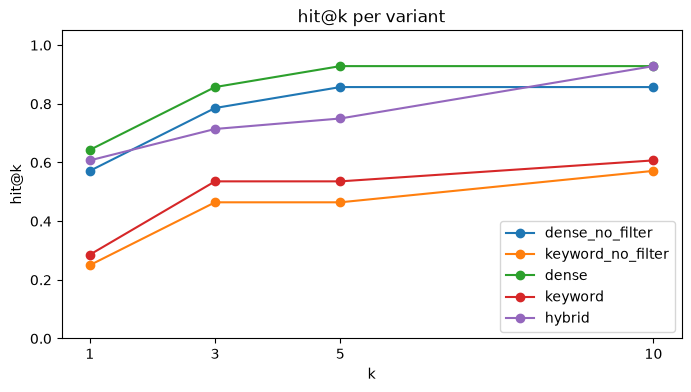

In [14]:
pl1 = evaluator.plot_metric("hit")

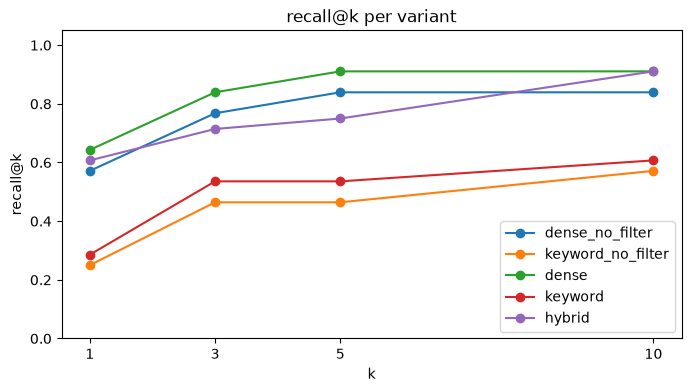

In [15]:
pl2 = evaluator.plot_metric("recall")

## Failures

Answerable questions the hybrid retriever missed, and what it retrieved instead.

In [9]:
with pl.Config(tbl_rows=100, tbl_cols=150, fmt_str_lengths=80):
    print(evaluator.failures("hybrid"))

shape: (2, 5)
┌───────────────────┬───────────────────┬───────────────────┬───────────────────┬──────────────────┐
│ id                ┆ question          ┆ expected          ┆ retrieved         ┆ retrieved_funds  │
│ ---               ┆ ---               ┆ ---               ┆ ---               ┆ ---              │
│ str               ┆ str               ┆ list[str]         ┆ list[str]         ┆ list[str]        │
╞═══════════════════╪═══════════════════╪═══════════════════╪═══════════════════╪══════════════════╡
│ rights_investor_e ┆ What rights do I  ┆ ["11074 p1-1"]    ┆ ["FU_BF065_EN     ┆ ["Enhanced       │
│ n                 ┆ have as an        ┆                   ┆ p508-508",        ┆ Intelligence     │
│                   ┆ investor in a     ┆                   ┆ "FU_BF065_EN      ┆ Global           │
│                   ┆ collective        ┆                   ┆ p309-310", …      ┆ Allocation       │
│                   ┆ investment scheme ┆                   ┆ "FU_BF065_EN   

## Inspect a single question

Full ranked list for one question/variant, marked relevant / on-fund.

In [10]:
question_id = evaluator.questions[0].id
evaluator.retrieved("hybrid", question_id)

rank,doc_id,pages,fund,section,relevant,on_fund,text
i64,str,str,str,str,bool,bool,str
1,"""18325""","""1-1""","""ОББ ЕкспертИйз Дефанзивен Конс…","""Резюме""",true,true,"""# Резюме ОББ ЕкспертИйз Дефан…"
2,"""18325""","""4-4""","""ОББ ЕкспертИйз Дефанзивен Конс…","""Инвестиционна стратегия""",false,true,"""# Инвестиционна стратегия Общ…"
3,"""18325""","""5-5""","""ОББ ЕкспертИйз Дефанзивен Конс…","""Инвестиционна стратегия""",false,true,"""Не е изключено временно да бъд…"
4,"""18325""","""5-5""","""ОББ ЕкспертИйз Дефанзивен Конс…","""Методология за положителен под…",false,true,"""# Методология за положителен п…"
5,"""18325""","""5-6""","""ОББ ЕкспертИйз Дефанзивен Конс…","""Дял на инвестициите""",false,true,"""Повече информация за MSCI Net …"
6,"""18325""","""4-4""","""ОББ ЕкспертИйз Дефанзивен Конс…","""Този подфонд""",false,true,"""# Екологични или социални хара…"
7,"""18325""","""5-5""","""ОББ ЕкспертИйз Дефанзивен Конс…","""Дял на инвестициите""",false,true,"""# Дял на инвестициите Подфонд…"
8,"""18325""","""7-7""","""ОББ ЕкспертИйз Дефанзивен Конс…","""(1) Показатели, свързани с ESG…",false,true,"""Целите, свързани с ESG, ще бъд…"
9,"""18325""","""7-7""","""ОББ ЕкспертИйз Дефанзивен Конс…","""(2) Показатели, свързани с инт…",false,true,"""• непреките емисии на парников…"
